In [33]:
from sklearn.model_selection import train_test_split
from sklearn import datasets

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd

plt.style.use("ggplot")

## Naïve Bayes classifiers

- A probabilistic classifier based on Bayes' Theorem with the assumption of feature independence.
- Trade-off: Faster training but slightly worse generalization than LogisticRegression & LinearSVC.  
- Efficiency: Learns parameters per feature individually, using simple per-class statistics.  
- Types in scikit-learn:  
  - GaussianNB: For continuous data.  
  - BernoulliNB: For binary data.  
  - MultinomialNB: For count-based data (e.g., word frequency in text).  
- Usage: text classification, spam filtering, and sentiment analysis

**Algorithm**

- Input: Dataset $D$ with features $X = \{X_1, X_2, ..., X_n\}$ and class labels $C_k$.  
- Calculate the prior probability of each class:  
$$
P(C_k) = \frac{\text{Count of samples in } C_k}{\text{Total number of samples}}
$$  
- For each feature $X_i$ given class $C_k$, compute the conditional probability $P(X_i | C_k)$  
- Compute the posterior probability for each class:  
$$
P(C_k | X) = \frac{P(X | C_k) P(C_k)}{P(X)}
$$  
- Make decision: Assign $X$ to the class $C_k$ with the *highest posterior probability*
$$
\hat{C} = \arg\max_{C_k} P(C_k) \prod_{i} P(X_i | C_k)
$$  

Critical assumption:  Features $X_i$ are conditionally independent given the class $C_k$ (often doesn't hold in real-world datasets):  
$$
P(X_1, X_2, ..., X_n | C_k) = P(X_1 | C_k) P(X_2 | C_k) ... P(X_n | C_k)
$$  

### Example: classifying emails as Spam or Non-Spam

- Data

| Email | Contains Free? | Contains Win? | Spam |
| ----- | -------------- | ------------- | ---- |
| E1    | Yes            | Yes           | Yes  |
| E2    | No             | Yes           | No   |
| E3    | Yes            | No            | No   |
| E4    | Yes            | Yes           | Yes  |

- **Question: If a new email contains both Free and Win, is it spam?**

- **Calculate prior probabilities**

$$
P(\text{S}) =  \frac{2}{4} = 0.5, 
P(\text{NS}) =  \frac{2}{4} = 0.5
$$


- **Calculate likelihood** $P(\text{Feature} | \text{Class})$ for each feature:

$$
P(\text{Free} | \text{S}) = \frac{\text{Spam emails with `Free'}}{\text{Total S Emails}} = \frac{2}{2} = 1.0
$$

$$
P(\text{Free} | \text{NS}) = \frac{1}{2} = 0.5
$$

$$
P(\text{Win} | \text{S}) = \frac{2}{2} = 1.0
$$

$$
P(\text{Win} | \text{NS}) = \frac{1}{2} = 0.5
$$

- **Calculate posterior probabilities using Naïve Bayes**

$$
P(\text{S} | \text{Free, Win}) \propto P(\text{S}) \times P(\text{Free} | \text{S}) \times P(\text{Win} | \text{S})= 0.5 \times 1.0 \times 1.0 = 0.5
$$

$$
P(\text{NS} | \text{Free, Win}) \propto P(\text{NS}) \times P(\text{Free} | \text{NS}) \times P(\text{Win} | \text{NS}) = 0.5 \times 0.5 \times 0.5 = 0.125
$$


- **Decision**: Since $P(\text{S} | \text{Free, Win})>P(\text{NS} | \text{Free, Win})$,  it's a spam email.

See also:

- [StatQuest's video](https://www.youtube.com/watch?v=O2L2Uv9pdDA)

In [34]:
# code adapted from https://scikit-learn.org/stable/modules/naive_bayes.html#naive-bayes. Please check it for details regarding implementations and parameters that you can tune.

from sklearn.naive_bayes import GaussianNB

X, y = datasets.load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8)
gnb = GaussianNB()
y_pred = gnb.fit(X_train, y_train).predict(X_test)
print(
    "Number of mislabeled points out of a total %d points : %d"
    % (X_test.shape[0], (y_test != y_pred).sum())
)

Number of mislabeled points out of a total 30 points : 1


## Decision Trees

- A hierarchy of if–else questions, represented by tree nodes and branches, that lead to a decision, or tree leaves. It's used for modeling classification and regression.
- Each root node represents an input variable and it's split point.
- Leaf nodes represent class labels and branches represent conjunctions of features leading to those labels.

### CART (Classification and Regression Trees)

#### Greedy Recursive Binary Splitting

- Divides the input space.
- Evaluates all input variables and split points to select the one with the lowest cost.
- cost function:
    - Regression: Sum of squared errors
    - Classification: Gini index (measures purity of leaf nodes)

##### Gini Index

- Measures "how mixed the data in a node is".
- A measure of how often a randomly chosen element of a set would be incorrectly labeled if it were labeled randomly and independently according to the distribution of labels in the set. 
- It becomes 0 when all cases in the node fall into a single target category.
- Consider a set of items has $J$ classes and relative frequencies $p_1, \cdots, p_J$ and the probability of miscategorizing that item is $\sum_{k \ne i} p_k = 1-p_i$. Then Gini index:

$$
{\rm I}_G(p) = \sum_{i=1}^J \left( p_i \sum_{k\neq i} p_k \right)
 = \sum_{i=1}^J p_i (1-p_i)
 = 1 - \sum^J_{i=1} p_i^2.
 $$
(see [wiki](https://en.wikipedia.org/wiki/Decision_tree_learning) and [this notes](https://www3.cs.stonybrook.edu/~cse352/L10basicDTalgorithm.pdf) for a broader discussion)

#### Pruning

- Stop the creation of the  tree early (pre-pruning)
- Remove nodes that contain little information (pruning)
- These prevent overfitting by controlling specificity to training data.
- Simpler trees are easier to interpret and generalize better. 

### Advantages

easily visualized and understood (interpretable). Also they work well with features having different scales, or a mix of binary and continuous features.


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",30
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Accuracy on training set = 1.0
Accuracy on test set: 0.9333333333333333
Feature importance: [0.02920926 0.         0.42958373 0.541207  ]


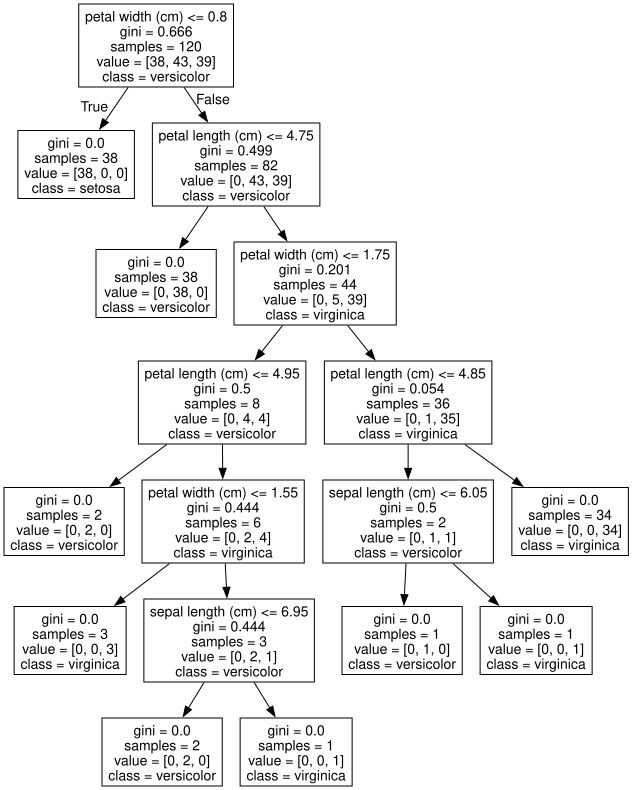

In [35]:
# code adapted from https://scikit-learn.org/stable/modules/tree.html#classification

from sklearn import tree
import graphviz

iris = datasets.load_iris()
X, y = iris.data, iris.target
clf = tree.DecisionTreeClassifier(
    max_depth=30
)  # (max_depth=3) # max depth and complexity (overfitting)
clf = clf.fit(X, y)
clf.fit(X_train, y_train)
print(f"Accuracy on training set = {clf.score(X_train, y_train)}")
print(f"Accuracy on test set: {clf.score(X_test, y_test)}")
print(f"Feature importance: {clf.feature_importances_}")
# "if a feature has a low feature_importance, it doesn’t mean that this feature  is uninformative. It only means that the feature was not picked by the tree, likely  because another feature encodes the same information." (Guido & Müller)
dot_data = tree.export_graphviz(
    clf, out_file=None, feature_names=iris.feature_names, class_names=iris.target_names
)
graph = graphviz.Source(dot_data)
graph

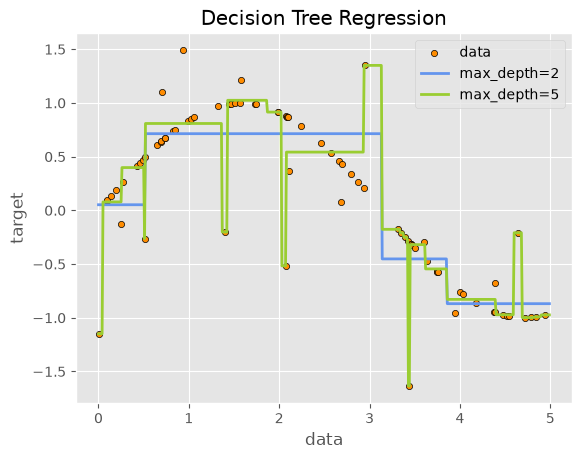

In [36]:
# A regression example
# code adapted from https://scikit-learn.org/stable/auto_examples/tree/plot_tree_regression.html

from sklearn.tree import DecisionTreeRegressor

rng = np.random.RandomState(1)
X = np.sort(5 * rng.rand(80, 1), axis=0)
y = np.sin(X).ravel()
y[::5] += 3 * (0.5 - rng.rand(16))

regr_1 = DecisionTreeRegressor(max_depth=2)
regr_2 = DecisionTreeRegressor(max_depth=5)
regr_1.fit(X, y)
regr_2.fit(X, y)

X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_1 = regr_1.predict(X_test)
y_2 = regr_2.predict(X_test)

plt.figure()
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(X_test, y_1, color="cornflowerblue", label="max_depth=2", linewidth=2)
plt.plot(X_test, y_2, color="yellowgreen", label="max_depth=5", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend();